In [33]:
model.fit(X, y)

training_predictions = model.predict(X)

training_mae = mean_absolute_error(
    y,
    training_predictions
)

training_rmse = np.sqrt(
    mean_squared_error(y, training_predictions)
)

print("Training MAE:", training_mae)
print("LOOCV MAE:", cv_mae)

print("Training RMSE:", training_rmse)
print("LOOCV RMSE:", cv_rmse)

Training MAE: 0.8889671992653808
LOOCV MAE: 1.6662975976130638
Training RMSE: 1.0163848865706429
LOOCV RMSE: 1.8040259255263402


In [32]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the provisional dataset
data = pd.read_csv("../data/mpcvd_experimental_data_v01.csv")

# Define predictors and response
X = data[["methane_pct", "temperature_c"]]
y = data["growth_rate_um_h"]

# Set up leave-one-out cross-validation
loo = LeaveOneOut()

model = LinearRegression()

# Generate held-out predictions
cv_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=loo
)

# Calculate errors
cv_mae = mean_absolute_error(y, cv_predictions)
cv_rmse = np.sqrt(mean_squared_error(y, cv_predictions))

print("LOOCV MAE:", cv_mae)
print("LOOCV RMSE:", cv_rmse)

LOOCV MAE: 1.6662975976130638
LOOCV RMSE: 1.8040259255263402


In [31]:
from sklearn.metrics import mean_squared_error, r2_score

# Linear model using methane concentration only
linear_model = LinearRegression()
linear_model.fit(X, y)

linear_predictions = linear_model.predict(X)

# Quadratic model predictions
quadratic_predictions = quadratic_model.predict(X_poly)

# Calculate fitting metrics
linear_rmse = np.sqrt(
    mean_squared_error(y, linear_predictions)
)

quadratic_rmse = np.sqrt(
    mean_squared_error(y, quadratic_predictions)
)

print("Linear RMSE:", linear_rmse)
print("Quadratic RMSE:", quadratic_rmse)

print("Linear R²:", r2_score(y, linear_predictions))
print("Quadratic R²:", r2_score(y, quadratic_predictions))

Linear RMSE: 1.2708210094779688
Quadratic RMSE: 0.7992012048713266
Linear R²: 0.08031135268953915
Quadratic R²: 0.6362656526185395


/Users/faseehatakolia/Documents/diamond-growth-optimisation/.venv/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


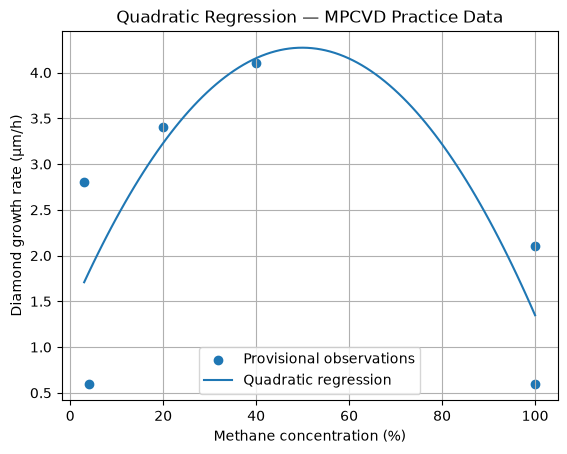

In [30]:
# Create methane concentrations for a smooth curve
methane_range = np.linspace(
    data["methane_pct"].min(),
    data["methane_pct"].max(),
    100
).reshape(-1, 1)

# Transform using the same polynomial features
methane_range_poly = poly.transform(methane_range)

# Predict growth rates
predicted_growth = quadratic_model.predict(methane_range_poly)

# Plot observations
plt.scatter(
    data["methane_pct"],
    data["growth_rate_um_h"],
    label="Provisional observations"
)

# Plot quadratic model
plt.plot(
    methane_range[:, 0],
    predicted_growth,
    label="Quadratic regression"
)

plt.xlabel("Methane concentration (%)")
plt.ylabel("Diamond growth rate (µm/h)")
plt.title("Quadratic Regression — MPCVD Practice Data")

plt.legend()
plt.grid(True)
plt.show()

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

data = pd.read_csv("../data/mpcvd_experimental_data_v01.csv")

X = data[["methane_pct"]]
y = data["growth_rate_um_h"]

# Generate methane and methane-squared features
poly = PolynomialFeatures(degree=2, include_bias=False)

X_poly = poly.fit_transform(X)

# Fit quadratic regression
quadratic_model = LinearRegression()
quadratic_model.fit(X_poly, y)

print("Intercept:", quadratic_model.intercept_)
print("Coefficients:", quadratic_model.coef_)

Intercept: 1.3702277124904234
Coefficients: [ 0.11628832 -0.00116506]


In [28]:
data.to_csv(
    "../results/linear_regression_results.csv",
    index=False
)

print("Regression results saved successfully.")

Regression results saved successfully.


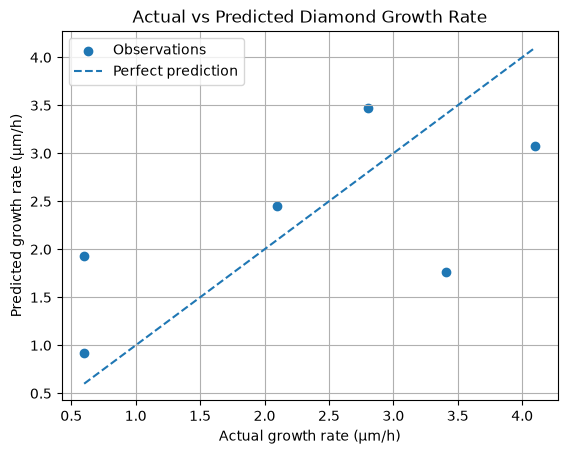

In [27]:
plt.scatter(
    y,
    predictions,
    label="Observations"
)

lower = min(y.min(), predictions.min())
upper = max(y.max(), predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "--",
    label="Perfect prediction"
)

plt.xlabel("Actual growth rate (µm/h)")
plt.ylabel("Predicted growth rate (µm/h)")
plt.title("Actual vs Predicted Diamond Growth Rate")

plt.legend()
plt.grid(True)
plt.show()

In [26]:
predictions = model.predict(X)

mae = mean_absolute_error(y, predictions)
rmse = np.sqrt(mean_squared_error(y, predictions))
r2 = r2_score(y, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 0.8889671992653808
RMSE: 1.0163848865706429
R²: 0.4117140848453824


In [25]:
data["predicted_growth"] = model.predict(X)

data["residual"] = (
    data["growth_rate_um_h"] - data["predicted_growth"]
)

print(
    data[
        [
            "growth_rate_um_h",
            "predicted_growth",
            "residual"
        ]
    ]
)

   growth_rate_um_h  predicted_growth  residual
0              0.60          1.931153 -1.331153
1              3.41          1.762088  1.647912
2              0.60          0.916759 -0.316759
3              2.80          3.471975 -0.671975
4              4.10          3.081011  1.018989
5              2.10          2.447014 -0.347014


In [24]:
model = LinearRegression()

model.fit(X, y)

print("Intercept:", model.intercept_)
print("Methane coefficient:", model.coef_[0])
print("Temperature coefficient:", model.coef_[1])

Intercept: -10.26862170798898
Methane coefficient: -0.010566611570247932
Temperature coefficient: 0.015302552066115702


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = pd.read_csv("../data/mpcvd_experimental_data_v01.csv")

X = data[["methane_pct", "temperature_c"]]
y = data["growth_rate_um_h"]

print("Predictors:")
print(X)

print("\nResponse:")
print(y)

Predictors:
   methane_pct  temperature_c
0            4            800
1           20            800
2          100            800
3            3            900
4           40            900
5          100            900

Response:
0    0.60
1    3.41
2    0.60
3    2.80
4    4.10
5    2.10
Name: growth_rate_um_h, dtype: float64


Intercept: 0.48
Slope: 0.08399999999999999


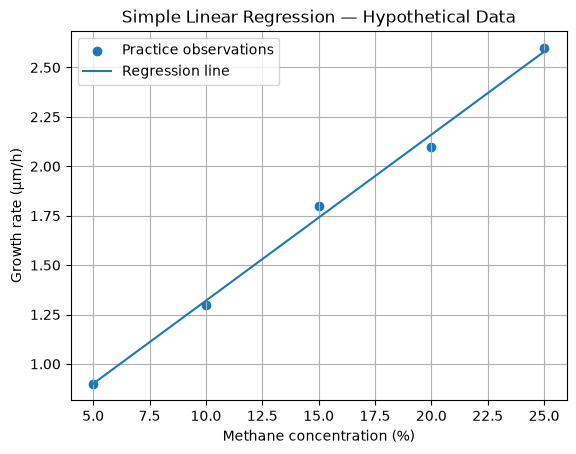

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Hypothetical practice data
methane = np.array([5, 10, 15, 20, 25]).reshape(-1, 1)
growth = np.array([0.9, 1.3, 1.8, 2.1, 2.6])

# Fit a regression model
model = LinearRegression()
model.fit(methane, growth)

# Display the coefficients
print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

# Calculate predictions
predictions = model.predict(methane)

# Plot observations and fitted line
plt.scatter(methane[:, 0], growth, label="Practice observations")
plt.plot(methane[:, 0], predictions, label="Regression line")

plt.xlabel("Methane concentration (%)")
plt.ylabel("Growth rate (µm/h)")
plt.title("Simple Linear Regression — Hypothetical Data")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
plt.savefig(
    "../results/diamond_growth_vs_methane.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [19]:
correlation = data["methane_pct"].corr(
    data["growth_rate_um_h"]
)

print("Pearson correlation:", correlation)

Pearson correlation: -0.283392576983836


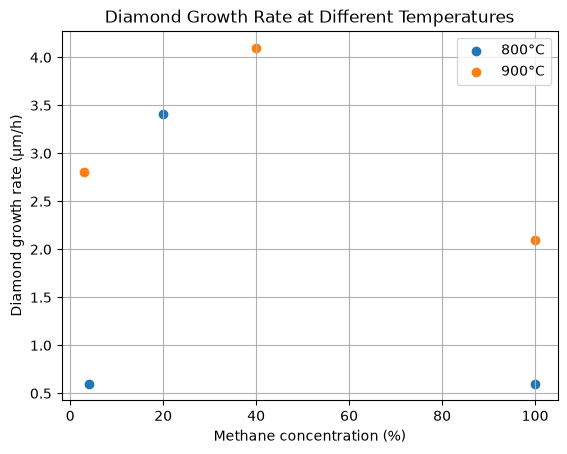

In [18]:
for temperature in data["temperature_c"].unique():

    subset = data[data["temperature_c"] == temperature]

    plt.scatter(
        subset["methane_pct"],
        subset["growth_rate_um_h"],
        label=f"{temperature}°C"
    )

plt.xlabel("Methane concentration (%)")
plt.ylabel("Diamond growth rate (µm/h)")
plt.title("Diamond Growth Rate at Different Temperatures")

plt.legend()
plt.grid(True)
plt.show()

Matplotlib is building the font cache; this may take a moment.


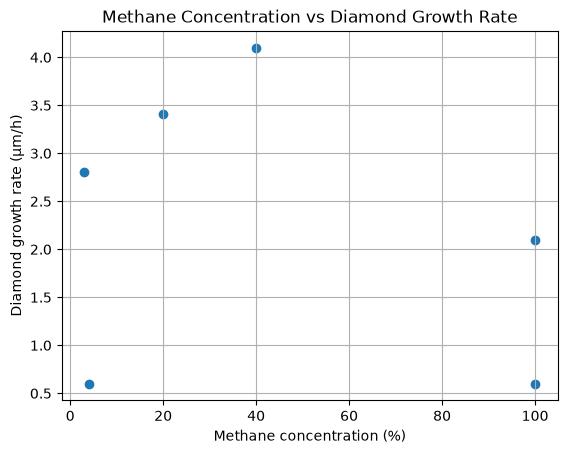

In [17]:
import matplotlib.pyplot as plt

plt.scatter(
    data["methane_pct"],
    data["growth_rate_um_h"]
)

plt.xlabel("Methane concentration (%)")
plt.ylabel("Diamond growth rate (µm/h)")
plt.title("Methane Concentration vs Diamond Growth Rate")

plt.grid(True)
plt.show()

In [16]:
growth = data["growth_rate_um_h"]

print("Mean:", growth.mean())
print("Median:", growth.median())
print("Standard deviation:", growth.std())
print("Minimum:", growth.min())
print("Maximum:", growth.max())

Mean: 2.268333333333333
Median: 2.45
Standard deviation: 1.4516255256320985
Minimum: 0.6
Maximum: 4.1


In [15]:
print("DATA VALIDATION SUMMARY")

print("Observations:", len(data))
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

print(
    "Negative growth rates:",
    (data["growth_rate_um_h"] < 0).sum()
)

print(
    "Invalid methane percentages:",
    (
        (data["methane_pct"] < 0)
        | (data["methane_pct"] > 100)
    ).sum()
)

DATA VALIDATION SUMMARY
Observations: 6
Missing values: 0
Duplicate rows: 0
Negative growth rates: 0
Invalid methane percentages: 0


In [14]:
print("Negative growth rates:")
print((data["growth_rate_um_h"] < 0).sum())

print("Methane percentages outside 0–100:")
print(
    (
        (data["methane_pct"] < 0)
        | (data["methane_pct"] > 100)
    ).sum()
)

print("Temperatures at or below absolute zero:")
print((data["temperature_c"] <= -273.15).sum())

Negative growth rates:
0
Methane percentages outside 0–100:
0
Temperatures at or below absolute zero:
0


In [13]:
print(data.dtypes)

observation_id        int64
temperature_c         int64
methane_pct           int64
growth_rate_um_h    float64
series_id             int64
dtype: object


In [12]:
print(
    data.duplicated(
        subset=["temperature_c", "methane_pct"],
        keep=False
    ).sum()
)

0


In [11]:
print(data.duplicated().sum())

0


In [10]:
print(data.isnull().sum())

observation_id      0
temperature_c       0
methane_pct         0
growth_rate_um_h    0
series_id           0
dtype: int64


In [9]:
import pandas as pd

data = pd.read_csv("../data/mpcvd_experimental_data_v01.csv")

In [8]:
print(data["growth_rate_um_h"].mean())
print(data["growth_rate_um_h"].max())
print(data["growth_rate_um_h"].min())

2.268333333333333
4.1
0.6


In [6]:
print(data.shape)
print(data.columns)
print(data.describe())

(6, 5)
Index(['observation_id', 'temperature_c', 'methane_pct', 'growth_rate_um_h',
       'series_id'],
      dtype='str')
       observation_id  temperature_c  methane_pct  growth_rate_um_h  series_id
count        6.000000       6.000000     6.000000          6.000000   6.000000
mean         3.500000     850.000000    44.500000          2.268333   2.500000
std          1.870829      54.772256    45.041092          1.451626   0.547723
min          1.000000     800.000000     3.000000          0.600000   2.000000
25%          2.250000     800.000000     8.000000          0.975000   2.000000
50%          3.500000     850.000000    30.000000          2.450000   2.500000
75%          4.750000     900.000000    85.000000          3.257500   3.000000
max          6.000000     900.000000   100.000000          4.100000   3.000000


In [5]:
import pandas as pd

data = pd.read_csv("../data/mpcvd_experimental_data_v01.csv")

print(data)

   observation_id  temperature_c  methane_pct  growth_rate_um_h  series_id
0               1            800            4              0.60          2
1               2            800           20              3.41          2
2               3            800          100              0.60          2
3               4            900            3              2.80          3
4               5            900           40              4.10          3
5               6            900          100              2.10          3


In [4]:
growth_time = 10

thickness = growth_rate * growth_time

print("Diamond thickness grown:", thickness, "µm")

Diamond thickness grown: 34.1 µm


In [2]:
# Experimental process conditions
temperature = 800
methane = 20
growth_rate = 3.41

print("Temperature:", temperature, "°C")
print("Methane concentration:", methane, "%")
print("Diamond growth rate:", growth_rate, "µm/h")

Temperature: 800 °C
Methane concentration: 20 %
Diamond growth rate: 3.41 µm/h


In [1]:
print("My Diamond Growth Optimisation Project is ready!")

My Diamond Growth Optimisation Project is ready!
